# 09 - Interpretasi Klaster

Menerjemahkan label klaster (angka) menjadi **profil yang bisa dibaca**: ciri
permintaan tiap klaster, namanya, produk yang jadi noise, dan seberapa sepakat
antar model. Memakai hasil notebook 01-06 dan 08 (`labels_*.csv`) bersama
`fitur_produk_outlet.csv`.

In [1]:
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score

folder = 'Clustering_Stok'
fitur = json.load(open(f'{folder}/meta.json'))['features']
asli = pd.read_csv(f'{folder}/fitur_produk_outlet.csv')

CIRI = ['mean_daily', 'cv', 'zero_day_ratio', 'max_daily', 'trend_weekly_pct',
        'weekend_ratio', 'momentum_30d', 'share_morning', 'share_evening',
        'loyalty_share', 'avg_price']

labels = {f.split('labels_')[1][:-4]: pd.read_csv(f)
          for f in sorted(glob.glob(f'{folder}/labels_*.csv'))}
print('Model   :', list(labels))
print('Produk  :', len(asli))

Model   : ['DBSCAN-cosine', 'DBSCAN-euclidean', 'DBSCAN-manhattan', 'HDBSCAN', 'KMeans-cosine', 'KMeans-euclidean', 'KMeans-manhattan']
Produk  : 282


## 1. Profil Tiap Klaster

Profil dihitung dari fitur **asli** (bukan skala z) agar angkanya bisa langsung
dibaca, misal `mean_daily` = rata-rata terjual per hari. Label `-1` (noise)
dipisah, bukan bagian klaster.

In [2]:
profil = {}
for nama, lab in labels.items():
    d = asli.merge(lab, on=['Outlet', 'Item'])
    d = d[d['cluster'] != -1]
    p = d.groupby('cluster')[CIRI].mean()
    p['jumlah'] = d.groupby('cluster').size()
    profil[nama] = p
    p.round(3).to_csv(f'{folder}/profil_klaster_{nama}.csv')
    print(f'\n== {nama} ==')
    print(p.round(2))


== DBSCAN-cosine ==
         mean_daily    cv  zero_day_ratio  max_daily  trend_weekly_pct  \
cluster                                                                  
0              1.18  0.93            0.31       5.36              0.00   
1              0.62  1.31            0.55       3.70              0.00   
2              0.79  1.13            0.46       4.00              0.01   

         weekend_ratio  momentum_30d  share_morning  share_evening  \
cluster                                                              
0                 1.02          0.93           0.30           0.42   
1                 0.99          0.92           0.25           0.44   
2                 1.21          1.02           0.20           0.44   

         loyalty_share  avg_price  jumlah  
cluster                                    
0                 0.02   21725.27      91  
1                 0.03   21832.30     161  
2                 0.00   21000.00       4  

== DBSCAN-euclidean ==
         mean

## 2. Penamaan Klaster

Nama dibentuk dari ciri yang paling menonjol antar klaster (z-score fitur
profil). Ini label deskriptif untuk laporan, bukan kategori baku.

In [3]:
def nama_klaster(z):
    dasar = 'Fast mover' if z['mean_daily'] > 0.5 else 'Slow mover' if z['mean_daily'] < -0.5 else 'Sedang'
    ciri = {'weekend_ratio': 'ramai akhir pekan', 'share_evening': 'sore-malam',
            'share_morning': 'pagi', 'loyalty_share': 'banyak gratis', 'cv': 'permintaan tak stabil'}
    kuat = [v for k, v in ciri.items() if z[k] > 0.5]
    return dasar + (' + ' + ', '.join(kuat[:2]) if kuat else '')

for nama, p in profil.items():
    z = (p[CIRI] - p[CIRI].mean()) / p[CIRI].std(ddof=0)
    gab = asli.merge(labels[nama], on=['Outlet', 'Item'])
    print(f'\n== {nama} ==')
    for k in p.index:
        contoh = gab[gab['cluster'] == k].nlargest(3, 'total_qty')['Item'].tolist()
        print(f'  Klaster {k} (n={int(p.loc[k, "jumlah"])}): {nama_klaster(z.loc[k])} | contoh: {", ".join(contoh)}')


== DBSCAN-cosine ==
  Klaster 0 (n=91): Fast mover + pagi | contoh: Jasmine (Hot), Jus Semangka, BLACK (Houseblend)
  Klaster 1 (n=161): Slow mover + sore-malam, banyak gratis | contoh: Jasmine (Ice), Apple Pie Latte, Butterscotch
  Klaster 2 (n=4): Sedang + ramai akhir pekan | contoh: Lemon Tea (Hot), Americano (Hot Houseblend), Cappuccino (Hot Houseblend)

== DBSCAN-euclidean ==
  Klaster 0 (n=238): Fast mover + sore-malam | contoh: Jus Semangka, BLACK (Houseblend), Hazelnut Latte (Gedhe)
  Klaster 1 (n=3): Slow mover + ramai akhir pekan, pagi | contoh: Cold Brew, Friendly Coffee (Hot double shot), WHITE

== DBSCAN-manhattan ==
  Klaster 0 (n=217): Fast mover + sore-malam | contoh: BLACK (Houseblend), Hazelnut Latte (Gedhe), Not Tiramisu Latte (Gedhe)
  Klaster 1 (n=3): Slow mover + ramai akhir pekan, pagi | contoh: Cold Brew, Friendly Coffee (Hot double shot), WHITE

== HDBSCAN ==
  Klaster 0 (n=8): Slow mover + pagi, permintaan tak stabil | contoh: Jasmine (Hot), Shakencano, Ameri

## 3. Produk Noise

Noise = pola permintaan yang tidak mirip klaster mana pun. Berguna untuk
pemantauan stok khusus, bukan untuk dibuang.

In [4]:
for nama, lab in labels.items():
    noise = lab[lab['cluster'] == -1]
    if noise.empty:
        continue
    d = asli.merge(noise, on=['Outlet', 'Item']).sort_values('total_qty', ascending=False)
    d.to_csv(f'{folder}/noise_{nama}.csv', index=False)
    print(f'{nama:<20} noise {len(d):>3} ({len(d) / len(lab) * 100:5.1f}%) | contoh: {", ".join(d.nlargest(5, "total_qty")["Item"])}')

DBSCAN-cosine        noise  26 (  9.2%) | contoh: Croffle, Friendly Coffee (Ice double shot), Basic Latte (Hot Houseblend), BLACK, Creamy Klepon
DBSCAN-euclidean     noise  41 ( 14.5%) | contoh: Jasmine (Hot), Chocolate (Ice), Espresso Houseblend (Basic Espresso), Croffle, Apple Pie Latte
DBSCAN-manhattan     noise  62 ( 22.0%) | contoh: Jasmine (Hot), Jus Semangka, Chocolate (Ice), Espresso Houseblend (Basic Espresso), Chocolate (Hot)
HDBSCAN              noise 129 ( 45.7%) | contoh: Jasmine (Hot), Jus Semangka, Chocolate (Ice), Espresso Houseblend (Basic Espresso), Upgrade Beans (Arabica)


## 4. Kesepakatan Antar Model (ARI)

Adjusted Rand Index mengukur seberapa mirip dua pengelompokan: 1 = identik,
0 = acak. Dipakai untuk melihat model mana yang sepakat. Noise `-1` dihitung
sebagai klaster tersendiri, jadi model dengan noise besar (HDBSCAN) wajar
skornya lebih rendah.

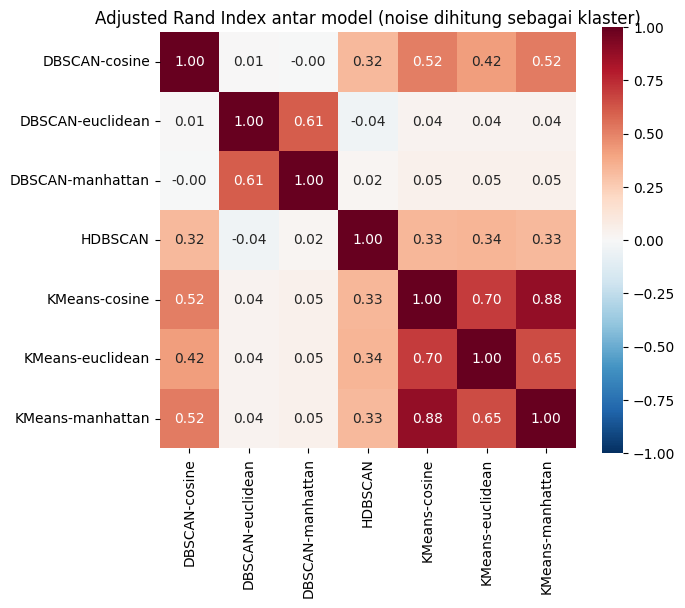

Paling sepakat : ('KMeans-cosine', 'KMeans-manhattan') (0.880)
Paling beda    : ('HDBSCAN', 'DBSCAN-euclidean') (-0.041)


In [5]:
nama_model = list(labels)
ari = pd.DataFrame(np.eye(len(nama_model)), index=nama_model, columns=nama_model)
for a in nama_model:
    for b in nama_model:
        ari.loc[a, b] = adjusted_rand_score(labels[a]['cluster'], labels[b]['cluster'])
ari.round(3).to_csv(f'{folder}/ari_matrix.csv')

plt.figure(figsize=(7, 6))
sns.heatmap(ari, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True)
plt.title('Adjusted Rand Index antar model (noise dihitung sebagai klaster)')
plt.tight_layout()
plt.show()

pasangan = ari.where(~np.eye(len(nama_model), dtype=bool)).stack().sort_values(ascending=False)
print('Paling sepakat :', pasangan.index[0], f'({pasangan.iloc[0]:.3f})')
print('Paling beda    :', pasangan.index[-1], f'({pasangan.iloc[-1]:.3f})')

## Kesimpulan

- Setiap klaster kini punya **profil angka + nama**, jadi hasil clustering bisa
  langsung dipakai untuk keputusan stok (fast mover perlu stok lebih, slow mover
  dikurangi).
- Daftar `noise_*.csv` menandai produk berpola tidak biasa untuk dipantau khusus.
- `ari_matrix.csv` menunjukkan tingkat kesepakatan antar model; K-Means antar
  metrik jarak biasanya paling mirip, sedangkan HDBSCAN paling berbeda karena
  noise-nya besar.